# Assignment 3: Ships in Satellite Imagery
In this assignment we will build & train a classical object detector using the Histogram of Orientated Gradients (HOG) Descriptor. We will use this object detector to solve the problem of identifying ships in satellite imagery using the dataset https://www.kaggle.com/rhammell/ships-in-satellite-imagery.  This dataset consists of images of ships and images of NOT ships and is therefore a binary classification problem. The NOT ship categories include partial ships and also linear image features such as roads, jetties, etc., that may be confused with ships.   

In this assignment you will write code for 3 main tasks (in numbered sections below) in order to the build a classical sliding window object detector:


1.   Create an appropriate HOG descriptor for the training images.
2.   Train a Support Vector Machine classifer to perform binary classification on the training set (after the training set is converted)
3. Create a sliding window detector to find ships in larger satellite image scenes.

This assignment demonstrates that classical image processing techniques may be used in preference to deep learning for certain applications. Particularly those that are limited in computational power or require fast execution.

![Ships in Satellite imagery](https://i.imgur.com/tLsSoTz.png)

This lab uses a **kaggle dataset**. **Please read** the [PDF](https://github.com/tonyscan6003/etivities/blob/main/kaggle_data_instructions.pdf) detailing how to setup your PC so that you can use a kaggle dataset within Colab. This assigment contains all the code necessary to read the downloaded kaggle files and to create image and label arrays with test and train splits.

# Dowload Kaggle Dataset.
The following code cells will download the kaggle ship-in-satellite-imagery dataset and unzip the file. (Ensure you have a valid kaggle API token stored on your PC as described in the PDF.)

In [216]:
# %pip install -q --upgrade kaggle

In [217]:
# Use this only if have problems with stale .json file
#!rm kaggle.json
#!rm ~/.kaggle/kaggle.*

In [218]:
#Choose the kaggle.json file that you downloaded
# ! mkdir ~/.kaggle

# Make directory named kaggle and copy kaggle.json file there.
# ! cp kaggle.json ~/.kaggle/

# Change the permissions of the file.
# ! chmod 600 ~/.kaggle/kaggle.json

# Load dataset
# ! kaggle datasets download rhammell/ships-in-satellite-imagery
# !unzip ships-in-satellite-imagery.zip > /dev/null
# !rm ships-in-satellite-imagery.zip

# HouseKeeping
 Import packages, helper functions to read from URL and import images.

In [219]:

from skimage import feature
from skimage import exposure
from sklearn import svm
from sklearn.model_selection import train_test_split
import numpy as np
import glob
import urllib.request
import cv2
import matplotlib.pyplot as plt


def url_to_image(url):
    resp = urllib.request.urlopen(url)
    temp_image = np.asarray(bytearray(resp.read()), dtype="uint8")
    temp_image = cv2.imdecode(temp_image, cv2.IMREAD_COLOR)
    temp_image = cv2.cvtColor(temp_image, cv2.COLOR_BGR2RGB) # OpenCV defaults to BGR, but we need RGB here..
    return temp_image

def read_image(image_url):
    image = url_to_image(image_url)
    x,y,z = np.shape(image)
    # Image is scaled to reduce computation time
    image = cv2.resize(image, dsize=(int(y/sf), int(x/sf)), interpolation=cv2.INTER_CUBIC)
    return image

In [220]:
# Read downloaded file list: Files are comprised of positive (ship) and negaitive (Not ship) examples

pos_img_list = glob.glob('shipsnet/shipsnet/1_*.png')
neg_img_list = glob.glob('shipsnet/shipsnet/0_*.png')


# Read Data
Read data from unzipped downloaded files and create the Training and Test sets.

In [221]:
# Set variables
n = 80 # number of x,y pixels in this image.
n_pts = 4000 # number of points to use (are 4000 in dataset, 1000 positive 3000 negative)

In [222]:
def read_images(img_list):
   train_pos = np.empty([1,n*n])
   # Function to read images from file list
   for i in range(len(img_list)):
      img_path = img_list[i]
      img = cv2.imread(img_path, cv2.IMREAD_COLOR)
      img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
      #  store image as row in array
      train_pos = (np.concatenate((train_pos,np.reshape(img, (1, n*n)))) if i>0 else  np.reshape(img, (1, n*n)))
   return train_pos

In [223]:
# Read positive and negative shp images into arrays
pos_img = read_images(pos_img_list)

neg_img = read_images(neg_img_list)


In [224]:
# create corresponding arrays of labels
y_pos_labels = np.ones(len(pos_img_list))
y_neg_labels = np.zeros(len(neg_img_list))

In [225]:
# Combine positive and negative images into one dataset.
dataset_img = np.concatenate((pos_img[0:1000,:],neg_img[0:3000,:]))
dataset_labels = np.append(y_pos_labels,y_neg_labels)

In [226]:
# Training examples
n_train = int(0.7*n_pts)

# Divide into training and test sets with labels
X_train, X_test, y_train, y_test = train_test_split(dataset_img, dataset_labels, train_size=n_train,
                                                    random_state=0,
                                                    stratify=dataset_labels)


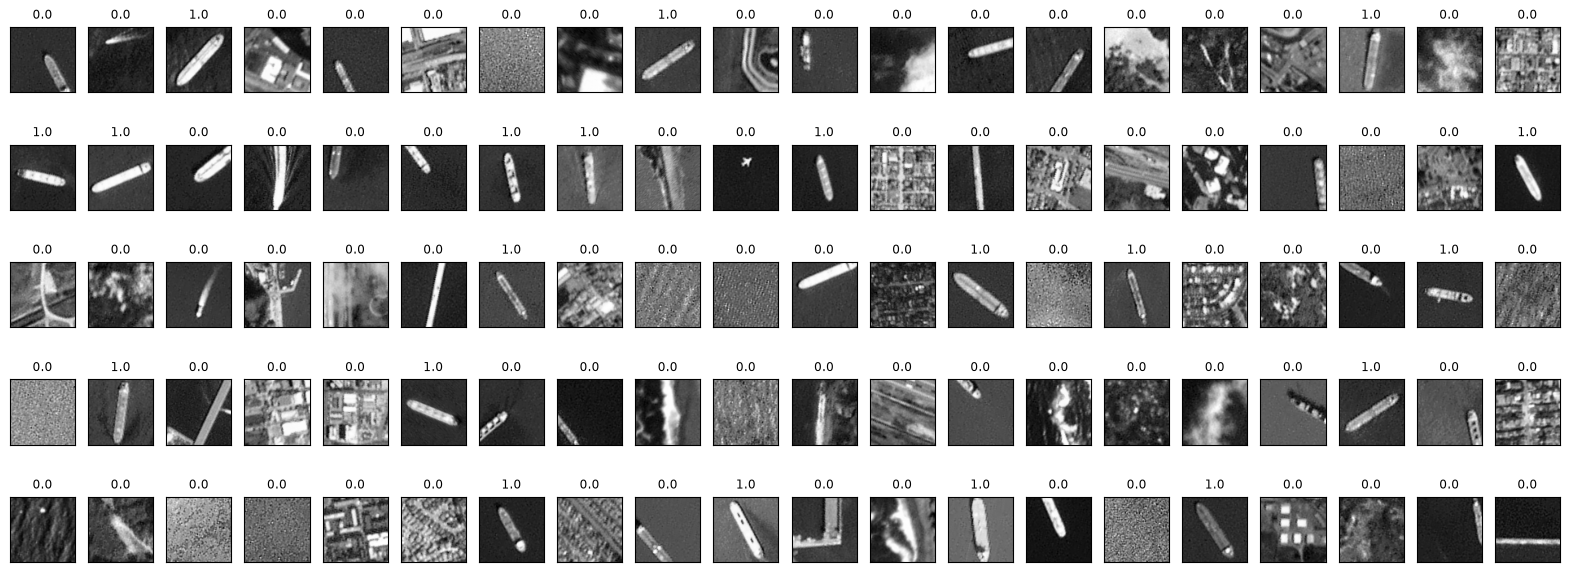

In [227]:
# Plot some examples from the training data
n_plots = 100 # number of plots
fig = plt.figure(figsize=(20, 15))
for i in range(n_plots):
    ax = fig.add_subplot(10, 20, i + 1, xticks=[], yticks=[])
    ax.imshow(np.reshape(X_train[i,0:n*n], (n, n)) ,'gray')
    ax.set_title(y_train[i],
                 fontsize='small')

# 1. HOG Descriptor
In order to obtain the HOG descriptor on each of the image patches during training we use the `feature.hog` command from [skimage](https://scikit-image.org/docs/dev/auto_examples/features_detection/plot_hog.html).

As in the pedestran detection case (see lesson 4 weeks 10 & 11) we will use the default HOG parameters e.g. 9 orientations in each histogram, 8 x 8 pixels in the cell and 2 x 2 cells per block are used. The size of the detector window in this case is chosen to be the same as the image size = 80 x 80 pixels. This is different to the pedestrian detector window size seen in the lessons.

Assuming that the blocks overlap:  
*   Calculate how many overlapping blocks are in the 80 x 80 detector window
*   Using the number of overlapping blocks and the other information above, determine the length of the HoG feature descriptor in this case.
*   Insert your value for the the length of the HoG feature descriptor in the code cell below.




In [228]:
# 80/8 = 10 cells per axis; overlapping 2x2 blocks give (10-1)^2 = 81 blocks.
# Each block has 2x2x9 = 36 values, so n_hog = 81x36 = 2916.
n_hog = 2916

In [229]:
# Function that outputs HoG descriptor
def hog_descriptor(img):
    # convert vector to img for HoG processing
    H = feature.hog(img, orientations=9, pixels_per_cell=(8, 8),
	  cells_per_block=(2, 2), transform_sqrt=True, block_norm="L1",
    visualize=False)
    return H

# Function that takes the training/test data and returns array of descriptors
def hog_des_arr(img_arr):
    img_des=np.zeros((len(img_arr),n_hog)) # Empty descriptor array to hold values
    i = 0                                  #pointer
    for img in img_arr:
      img = np.reshape(img[0:n*n], (n, n))  # convert training data vectors to rectangular image
      img_des[i,0:n_hog] = hog_descriptor(img)
      i=i+1
    return img_des

We then convert each of the image patches to it's HOG descriptor. We assign each of these descriptor vectors to the 2D arrays `X_train_des` and `X_test_des` which are now our training & test data.

In [230]:
X_train_des = hog_des_arr(X_train)
X_test_des = hog_des_arr(X_test)

In [231]:
print(np.shape(X_train))
print(np.shape(X_train_des))

(2800, 6400)
(2800, 2916)


 # 2. Training & Test SVM Classifier
 In this section we will train a support vector machine on the data we have converted to it's HOG descriptor. Using descriptors improves classification accuracy compared to using the raw image pixels.

In the code cell below utilise the [sklearn support vector machine](https://scikit-learn.org/stable/modules/svm.html) object and methods to train a support vector machine on the labelled trainig data (X_train_des,y_train).

In [232]:
# Setup Classifier
clf = svm.SVC(kernel="linear")

#Train on Data
clf.fit(X_train_des, y_train)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Test your classifier using the test dataset and obtain a [classification report](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-report).


In [233]:
# predict output labels.
y_pred = clf.predict(X_test_des)


In [234]:
# Classification Report
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Not ship", "Ship"]))


              precision    recall  f1-score   support

    Not ship       0.99      0.99      0.99       900
        Ship       0.96      0.96      0.96       300

    accuracy                           0.98      1200
   macro avg       0.97      0.97      0.97      1200
weighted avg       0.98      0.98      0.98      1200



We can plot some example from the test set using the code cell below.

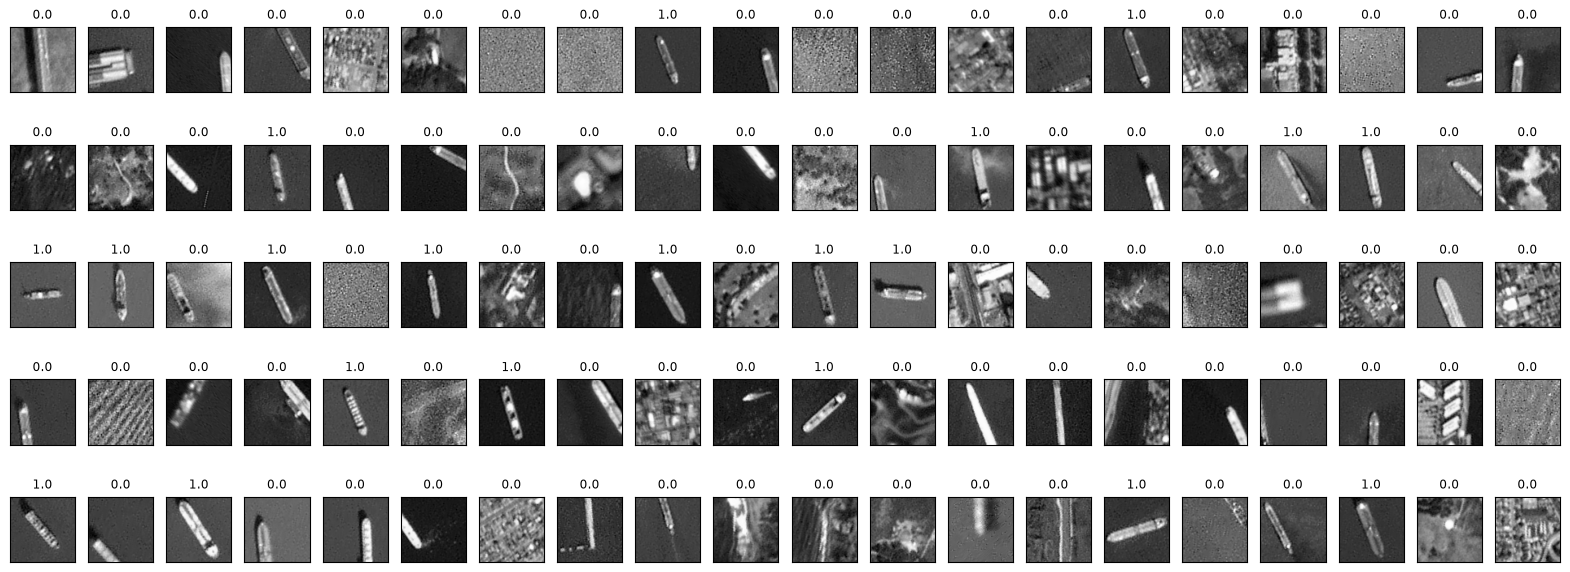

In [235]:


n_plots = 30 # number of plots
fig = plt.figure(figsize=(20, 15))
for i in range(100):
    ax = fig.add_subplot(10, 20, i + 1, xticks=[], yticks=[])
    ax.imshow( np.reshape(X_test[i,0:n*n], (n, n)) ,'gray')
    color = ('black' if y_pred[i] == y_test[i] else 'red')
    ax.set_title(y_test[i],
                 fontsize='small', color=color)

              precision    recall  f1-score   support

    Not ship     0.9856    0.9867    0.9861       900
        Ship     0.9599    0.9567    0.9583       300

    accuracy                         0.9792      1200
   macro avg     0.9727    0.9717    0.9722      1200
weighted avg     0.9791    0.9792    0.9792      1200



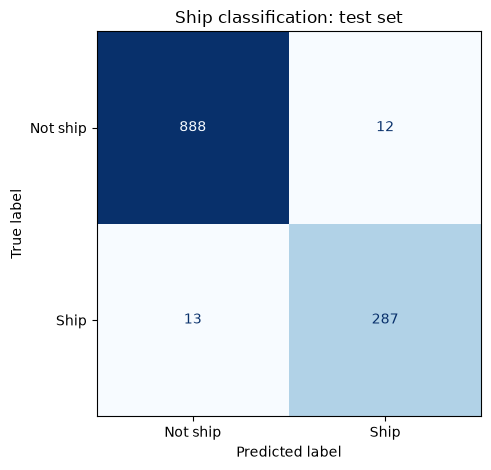

In [236]:
# Exact test results and confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

print(classification_report(y_test, y_pred, target_names=["Not ship", "Ship"], digits=4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=["Not ship", "Ship"],
    cmap="Blues", values_format="d", colorbar=False
)
plt.title("Ship classification: test set")
plt.tight_layout()
plt.show()


Misclassified test patches: 25 total; displaying 24.


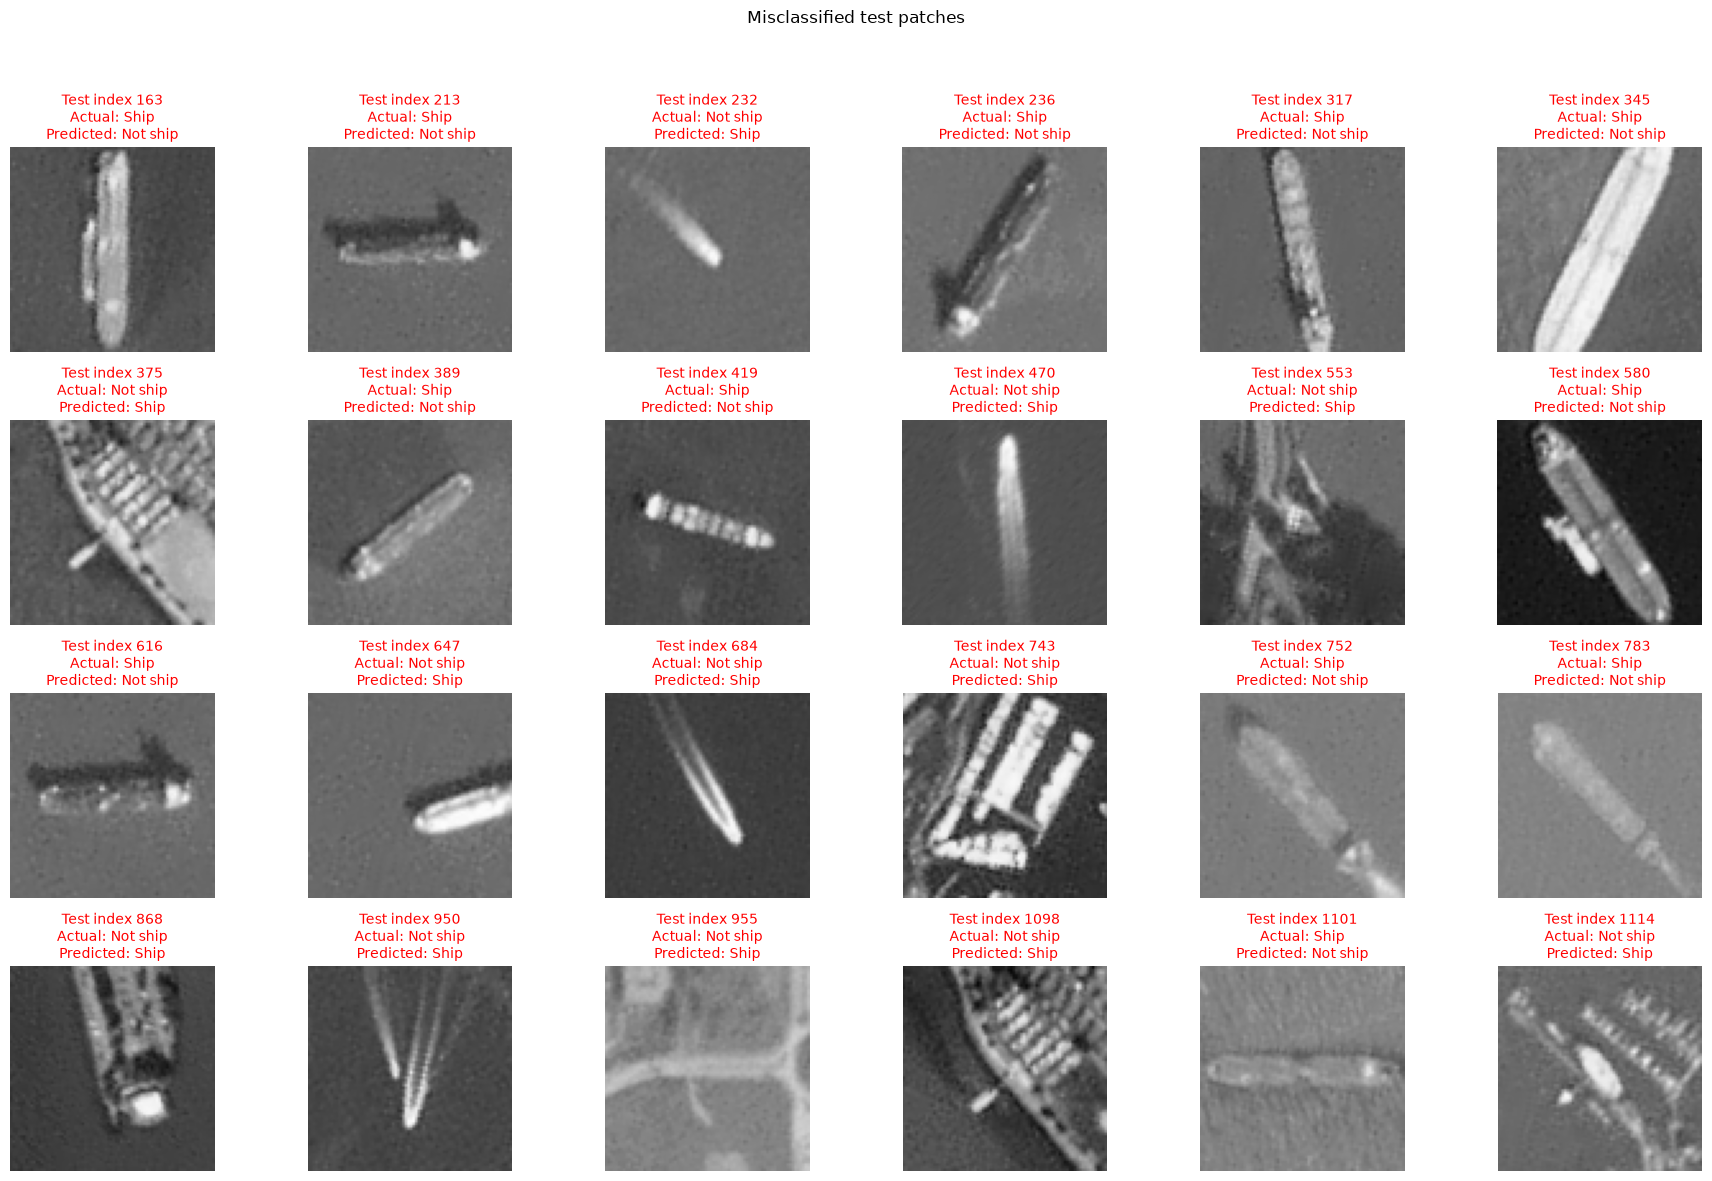

In [237]:
# Display selected test patches with actual and predicted labels.
def show_test_gallery(indices, title, title_color, max_images=24):
    selected = indices[:max_images]
    print(f"{title}: {len(indices)} total; displaying {len(selected)}.")
    if len(selected) == 0:
        return

    columns = min(6, len(selected))
    rows = (len(selected) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 3 * rows), squeeze=False)
    class_names = {0: "Not ship", 1: "Ship"}
    for ax in axes.flat:
        ax.axis("off")
    for ax, index in zip(axes.flat, selected):
        ax.imshow(X_test[index].reshape(n, n), cmap="gray", vmin=0, vmax=255)
        ax.set_title(
            f"Test index {index}\nActual: {class_names[int(y_test[index])]}\n"
            f"Predicted: {class_names[int(y_pred[index])]}",
            color=title_color, fontsize=10
        )
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

error_indices = np.flatnonzero(y_pred != y_test)
show_test_gallery(error_indices, "Misclassified test patches", "red")


Correctly identified ships: 287 total; displaying 24.


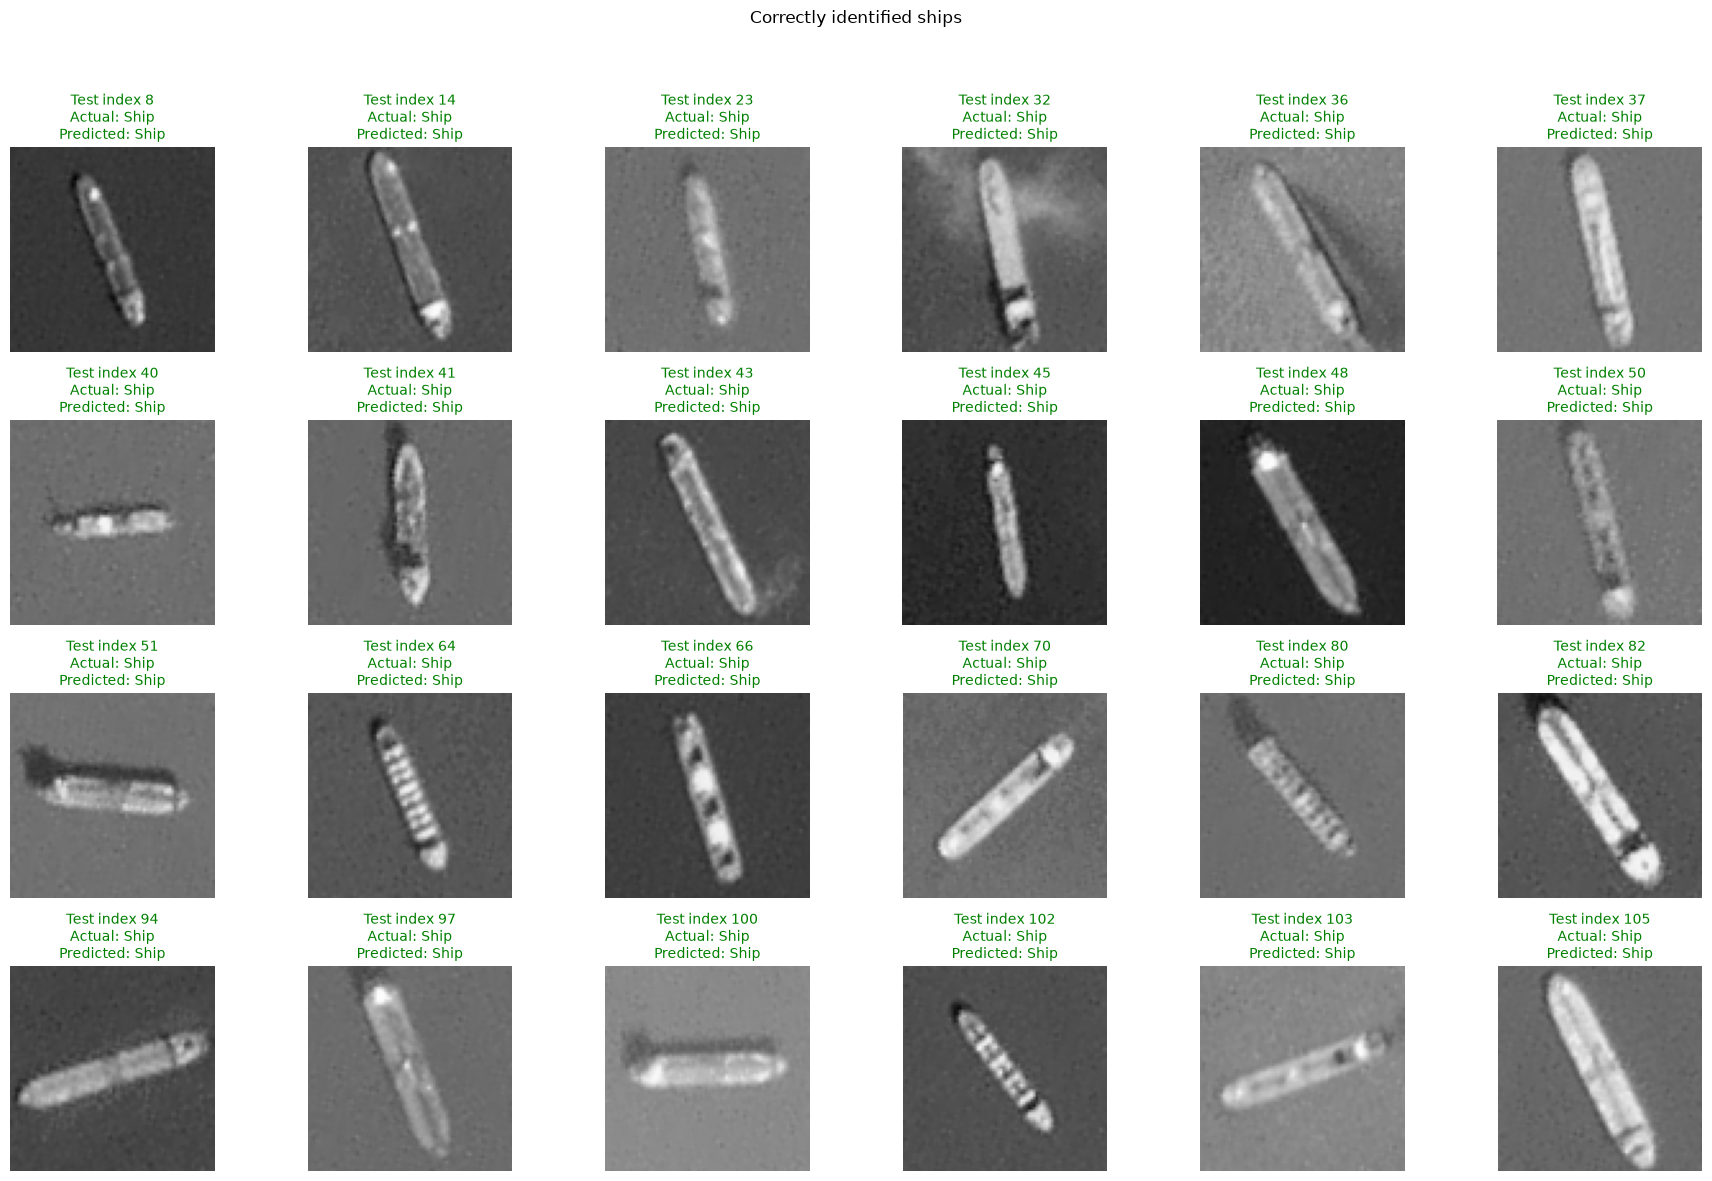

In [238]:
# True positives: actual ships that were correctly classified as ships.
correct_ship_indices = np.flatnonzero((y_test == 1) & (y_pred == 1))
show_test_gallery(correct_ship_indices, "Correctly identified ships", "green")


# 3. Use Classifier as a basic object Detector with a sliding window.
Now that we have a trained SVM and HoG descriptor, these components can be used as the basis of a sliding window detector. The sliding window can be used to automatically detect & mark the location of ships in a large satellite image view.

**Import scene:** We can perform object detection of ships in the scene imported in the code cell below. You can use grey scale version of the image gray_img in your sliding window detector, bounding boxes can be applied to the colour version of the image.

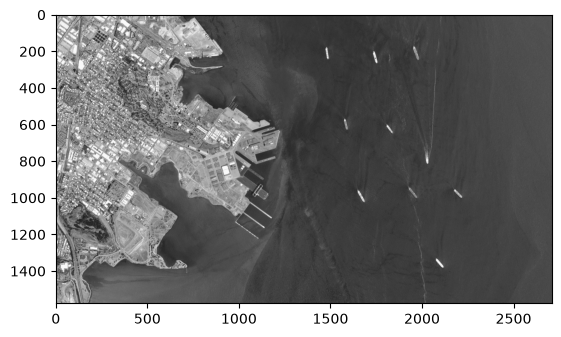

In [239]:
img_path = 'scenes/scenes/sfbay_3.png'
col_img = cv2.imread(img_path, cv2.IMREAD_COLOR)
gray_img = cv2.cvtColor(col_img, cv2.COLOR_BGR2GRAY)
plt.imshow( gray_img ,'gray')

In the code cell below you can code the sliding window function `sliding_window` which operates on the scene image. You can run your detector over the entire image pixel range, there is no need to make any special accomodation for the image border. The function outputs the array m x 4, where m is the number of bounding boxes detected.


*Step Size*
> The sliding window which is the same size as our training images `n` = 80, is moved around the image according to the value of the parameter `step_size` which you can set to an optimimum size. Larger step values may cause an object to be missed, however using a larger step size will increase the speed of execution which is useful to debug your algorithm. When a smaller step size is used, multiple detections of the same object can occur.

*Coordinate Systems*

> The greyscale input image that we are applying our sliding window detector to is a matrix. The elements of this matrix are accessed as (row,column). In order to successfully plot the bouding box using OpenCV rectangle commands, the bounding boxes must be output in a format [x1,y1,x2,y2] where x1,y1 correspond to the top left hand side corner of the bouding box and x2,y2 the bottom right corner. Thus the x coordinate of the bounding box corresponds to the column of the matrix and the y coordinate the rows. The origin (0,0) in the coordinate system used by OpenCV is the top left of the image.

*Non Maximal Supression*

>  We can use the `non_max_supression` function from the `imutils` package to remove overlapping detections. (This is already implemented in the code cell below that displays the bouding boxes you find)  

*Image Pyramid*

> We will not include a image pyramid in our object detector. As the test scene images are taken from fixed position satellite images similar to the training patches, there is no need to adjust the scale of the image.

In [240]:
# Detection window size and stride
windowSize = (n,n)
step_size = 10


### COMPLETE THE SLIDING WINDOW FUNCTION HERE ###

# SVM decision margin, not a probability. Set to 0.0 for the initial detector.
step_size = 8
decision_threshold = 1.0
nms_overlap_threshold = 0.1

def sliding_window(image):
   """
    image: input satellite image of arbitary size
    found_boxes: m x 4 array of output bounding boxes.
                 Each row corresponds to a bounding box [x1,y2,x2,y2]
                 (see note on coordinate system above)
   """

   found_boxes = []
   window_width, window_height = windowSize
   height, width = image.shape[:2]

   # Only full windows have the same HOG geometry as the training patches.
   for y in range(0, height - window_height + 1, step_size):
      for x in range(0, width - window_width + 1, step_size):
         patch = image[y:y + window_height, x:x + window_width]
         descriptor = hog_descriptor(patch).reshape(1, -1)
         if clf.decision_function(descriptor)[0] > decision_threshold:
            found_boxes.append([x, y, x + window_width, y + window_height])

   # Keep the required (m, 4) shape even when no ships are found.
   found_boxes = np.asarray(found_boxes, dtype=int).reshape(-1, 4)

   return found_boxes

You can run your function to output all the bounding boxes from the detections made by the classifier in the image.

In [241]:
found_boxes = sliding_window(gray_img)

The non_max_supression function from the imutils package is used to remove overlapping boxes. The boxes are overlaid on the color version of the satellite image.

Before suppression, we had 36 bounding boxes, after suppression we have 25


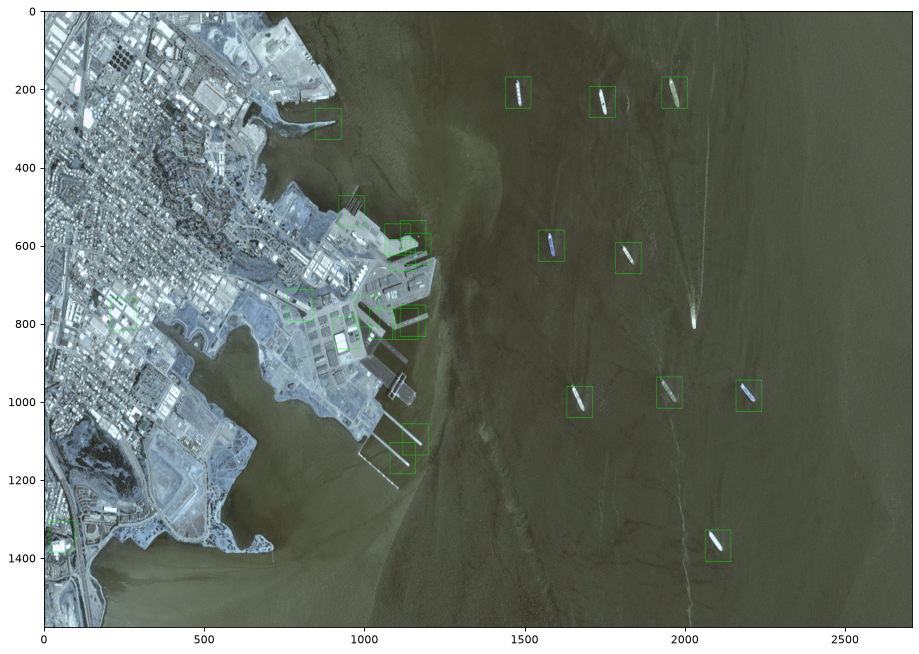

In [242]:
from imutils.object_detection import non_max_suppression

#Bounding box parameters
greenColor = (0, 255, 0)
lineThickness = 4

# run non-max suppression on these based on an overlay op 65%
nmsBoundingBoxes = non_max_suppression(found_boxes, probs=None, overlapThresh=0.65)

print ("Before suppression, we had {} bounding boxes, after suppression we have {}".format(len(found_boxes), len(nmsBoundingBoxes)))

greenColor = (0, 255, 0)
lineThickness = 1
# draw the final bounding boxes
for (xA, yA, xB, yB) in nmsBoundingBoxes:
    cv2.rectangle(col_img, (xA, yA), (xB, yB), greenColor, lineThickness)

# Plot figures
plt.figure(figsize=(14, 10), dpi=80)
plt.imshow(col_img, aspect='auto')
plt.show()

## Detector experiments

The linear SVM gave about 98% test accuracy, but the first scene result had many boxes on harbour structures. Testing C did not improve the final choice, so I kept C=1 and the original HOG settings.

I compared strides of 10 and 8, decision thresholds from 0.4 to 1.0, and suppression thresholds of 0.65, 0.35 and 0.1. A stride of 8 gave better alignment around the ships. The final display uses a decision threshold of 1.0 and suppression threshold of 0.1, with stronger SVM scores taking priority when boxes overlap.

This reduced the scene result from 142 boxes initially to 19, while keeping the main visible ships in open water. Some false detections remain around the harbour. These settings were selected by inspecting this scene; they have not been verified on unseen scenes.

The stricter threshold is a tradeoff: test patch ship precision rises to 99.15%, but recall falls to 77.33%. It is a decision score, not a probability. The original classification report uses the default threshold; the report below uses the detector threshold.

The original display cell is preserved. The final cell below shows the selected suppression settings. Earlier configurations are saved in `experiments/`.


Detector decision threshold: 1.0
              precision    recall  f1-score   support

    Not ship     0.9296    0.9978    0.9625       900
        Ship     0.9915    0.7733    0.8689       300

    accuracy                         0.9417      1200
   macro avg     0.9605    0.8856    0.9157      1200
weighted avg     0.9451    0.9417    0.9391      1200



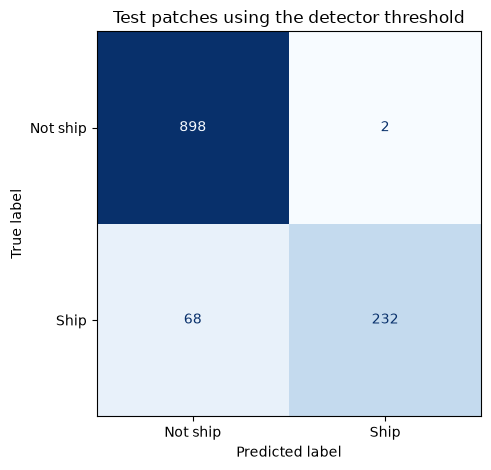

In [243]:
# Evaluate the same acceptance rule used by the sliding window detector.
detection_predictions = (clf.decision_function(X_test_des) > decision_threshold).astype(int)
print(f"Detector decision threshold: {decision_threshold}")
print(classification_report(y_test, detection_predictions, target_names=["Not ship", "Ship"], digits=4))
ConfusionMatrixDisplay.from_predictions(
    y_test, detection_predictions, labels=[0, 1], display_labels=["Not ship", "Ship"],
    cmap="Blues", values_format="d", colorbar=False
)
plt.title("Test patches using the detector threshold")
plt.tight_layout()
plt.show()


36 detections before suppression; 19 final boxes.


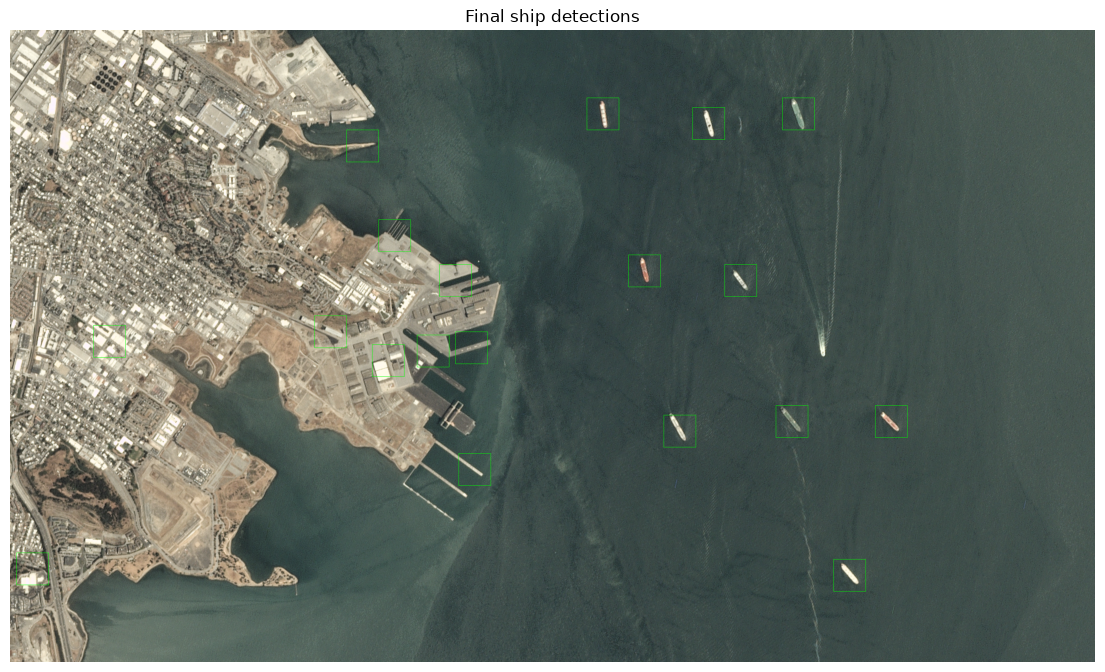

In [244]:
# Final display using the selected suppression settings.
found_scores = np.array([
    clf.decision_function(hog_descriptor(gray_img[y1:y2, x1:x2]).reshape(1, -1))[0]
    for x1, y1, x2, y2 in found_boxes
])
final_boxes = non_max_suppression(
    found_boxes, probs=found_scores, overlapThresh=nms_overlap_threshold
)
final_image = cv2.imread(img_path, cv2.IMREAD_COLOR)
for x1, y1, x2, y2 in final_boxes:
    cv2.rectangle(final_image, (x1, y1), (x2, y2), (0, 255, 0), 1)
print(f"{len(found_boxes)} detections before suppression; {len(final_boxes)} final boxes.")
plt.figure(figsize=(14, 10))
plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
plt.title("Final ship detections")
plt.axis("off")
plt.show()
